<a href="https://colab.research.google.com/github/sneha121083-dotcom/AI_Cyber_threatDetection/blob/main/Explainable_AI_Cyber_Threat_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Install the required libraries

!pip install -q pandas numpy matplotlib seaborn scikit-learn
!pip install -q xgboost shap networkx
!pip install -q torch-geometric


In [ ]:

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Explainable AI
import shap

# Graph processing
import networkx as nx

# Deep Learning
import torch
import torch.nn as nn

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


All libraries imported successfully!
PyTorch version: 2.14.1+cpu
GPU available: False


In [ ]:
#connecting google drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', '30_ENG25AM0493.pdf', 'IMG-20260510-WA0001 (1).jpg', 'IMG-20260510-WA0001.jpg', 'IMG-20260510-WA0000.jpg', 'SNEH2006.pdf', 'Screenshot_2026-08-11-12-38-26-23_40deb401b9ffe8e1df2f1cc5ba480b12.jpg', 'Scan documents20260811_123939.pdf', 'MS.pdf', 'SIH registration form 2026 (1).xlsx', 'SIH registration form 2026.xlsx', '26-A(ENG25AM0493)_AIML-G.pdf', 'CICIDS2017']


In [ ]:
dataset_path = "/content/drive/MyDrive/CICIDS2017"

print(os.listdir(dataset_path))

['MachineLearningCSV.zip', 'MachineLearningCVE']


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".zip"):
            print(os.path.join(root, file))

In [ ]:

import os

dataset_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCSV.zip"

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/CICIDS2017"

for file in os.listdir(dataset_path):
    print(file)

MachineLearningCSV.zip
MachineLearningCVE


In [ ]:
import zipfile
import os

for file in os.listdir(dataset_path):
    if file.endswith(".zip"):
        zip_path = os.path.join(dataset_path, file)

        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(dataset_path)

        print("Extracted:", file)

Extracted: MachineLearningCSV.zip


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".csv"):
            print(file)

Wednesday-workingHours.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/CICIDS2017"

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:
file_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (529918, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Statistical information
df.describe()


Rows: 529918
Columns: 79

Column Names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Fla

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,529918.000000,5.299180e+05,529918.000000,529918.000000,5.299180e+05,5.299180e+05,529918.000000,529918.000000,529918.000000,529918.000000,...,529918.000000,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05,5.299180e+05
mean,10644.367112,1.038927e+07,10.390315,11.517105,5.324195e+02,1.789841e+04,190.897188,20.277279,50.744078,57.452269,...,7.412509,-3.614576e+03,6.843482e+04,4.321930e+04,1.453907e+05,4.380369e+04,3.463918e+06,2.024408e+05,3.620657e+06,3.274066e+06
std,21390.213475,2.875195e+07,892.412791,1173.318788,6.228642e+03,2.675470e+06,448.833754,36.275793,91.964713,146.518081,...,851.762351,5.526328e+05,5.872322e+05,3.971455e+05,1.028606e+06,4.993677e+05,1.297057e+07,2.170149e+06,1.340649e+07,1.273216e+07
min,0.000000,-1.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,-8.388531e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,53.000000,1.760000e+02,2.000000,1.000000,1.800000e+01,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,0.000000,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.000000,3.130300e+04,2.000000,2.000000,6.800000e+01,1.440000e+02,40.000000,6.000000,38.000000,0.000000,...,1.000000,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,443.000000,3.557448e+05,4.000000,3.000000,1.870000e+02,3.920000e+02,83.000000,40.000000,53.000000,26.162951,...,3.000000,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,65535.000000,1.200000e+08,219759.000000,291922.000000,1.323378e+06,6.554530e+08,23360.000000,2293.000000,4638.923469,7125.596846,...,213557.000000,1.260000e+02,1.016597e+08,6.434950e+07,1.016597e+08,1.016597e+08,1.199997e+08,7.514502e+07,1.199997e+08,1.199997e+08


In [ ]:

print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nAttack Distribution:")
print(df.iloc[:, -1].value_counts())


Missing Values:
Flow Bytes/s                    64
 Flow Duration                   0
 Destination Port                0
 Total Backward Packets          0
Total Length of Fwd Packets      0
 Total Length of Bwd Packets     0
 Total Fwd Packets               0
 Fwd Packet Length Max           0
 Fwd Packet Length Min           0
 Fwd Packet Length Std           0
 Fwd Packet Length Mean          0
Bwd Packet Length Max            0
 Bwd Packet Length Min           0
 Bwd Packet Length Mean          0
 Bwd Packet Length Std           0
 Flow Packets/s                  0
 Flow IAT Mean                   0
 Flow IAT Std                    0
 Flow IAT Max                    0
 Flow IAT Min                    0
dtype: int64

Duplicate Rows: 26935

Attack Distribution:
 Label
BENIGN    529918
Name: count, dtype: int64


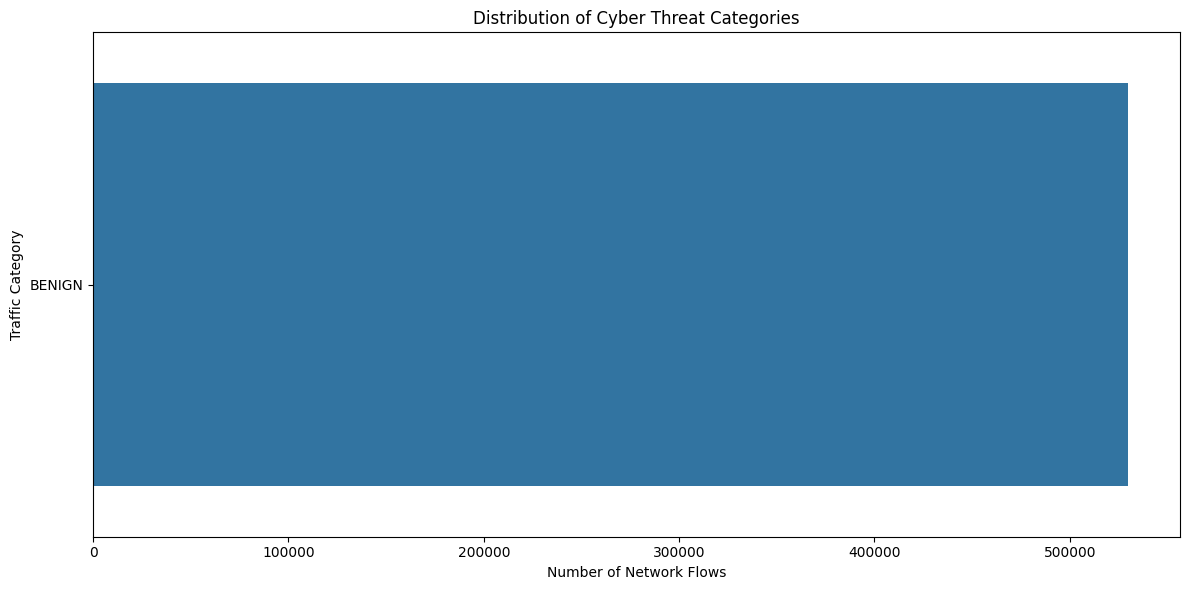

In [ ]:
df.columns=df.columns.str.strip()
label_column = "Label"

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y=label_column,
    order=df[label_column].value_counts().index
)

plt.title("Distribution of Cyber Threat Categories")
plt.xlabel("Number of Network Flows")
plt.ylabel("Traffic Category")
plt.tight_layout()
plt.show()


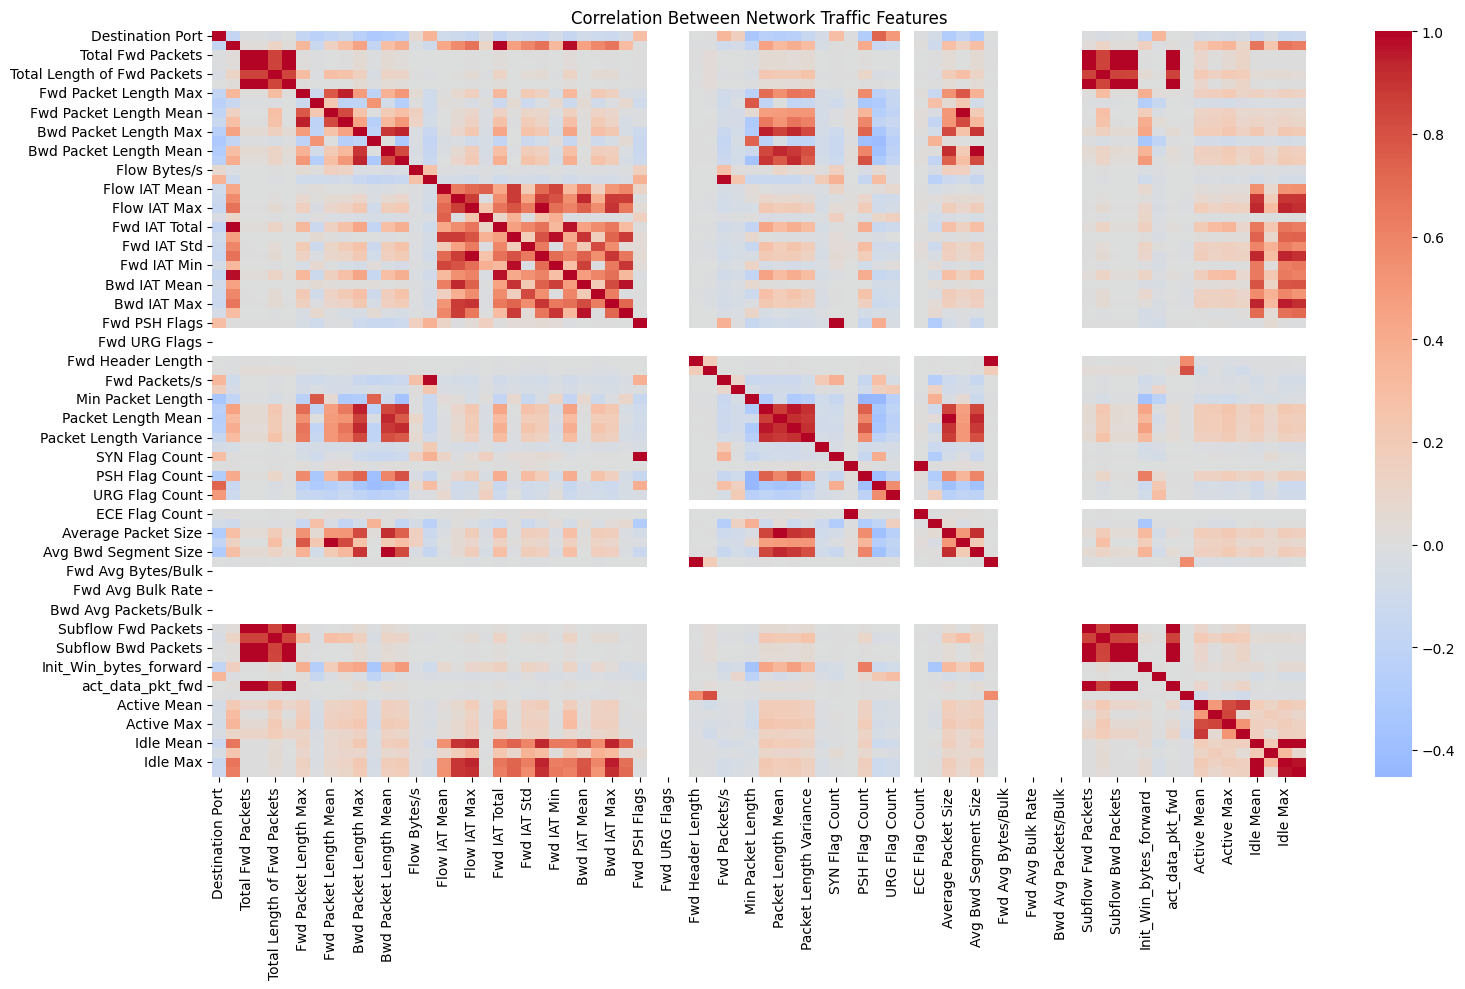

In [ ]:

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Network Traffic Features")
plt.tight_layout()
plt.show()


In [ ]:

# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Clean labels
df["Label"] = df["Label"].astype(str).str.strip()

# Replace infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Check missing values
print("Missing values:", df.isnull().sum().sum())

# Remove rows with missing values for initial experiment
df = df.dropna()

print("Cleaned dataset shape:", df.shape)


Missing values: 666
Cleaned dataset shape: (502650, 79)


In [ ]:

# Convert labels into binary classes

df["Target"] = (df["Label"] != "BENIGN").astype(int)

# Separate features and target
X = df.drop(columns=["Label", "Target"])

# Keep only numerical features
X = X.select_dtypes(include=np.number)

y = df["Target"]

print("Feature shape:", X.shape)
print("Target distribution:")
print(y.value_counts())


Feature shape: (502650, 78)
Target distribution:
Target
0    502650
Name: count, dtype: int64


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (402120, 78)
Testing samples: (100530, 78)


In [ ]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 1.0
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    100530

    accuracy                           1.00    100530
   macro avg       1.00      1.00      1.00    100530
weighted avg       1.00      1.00      1.00    100530



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


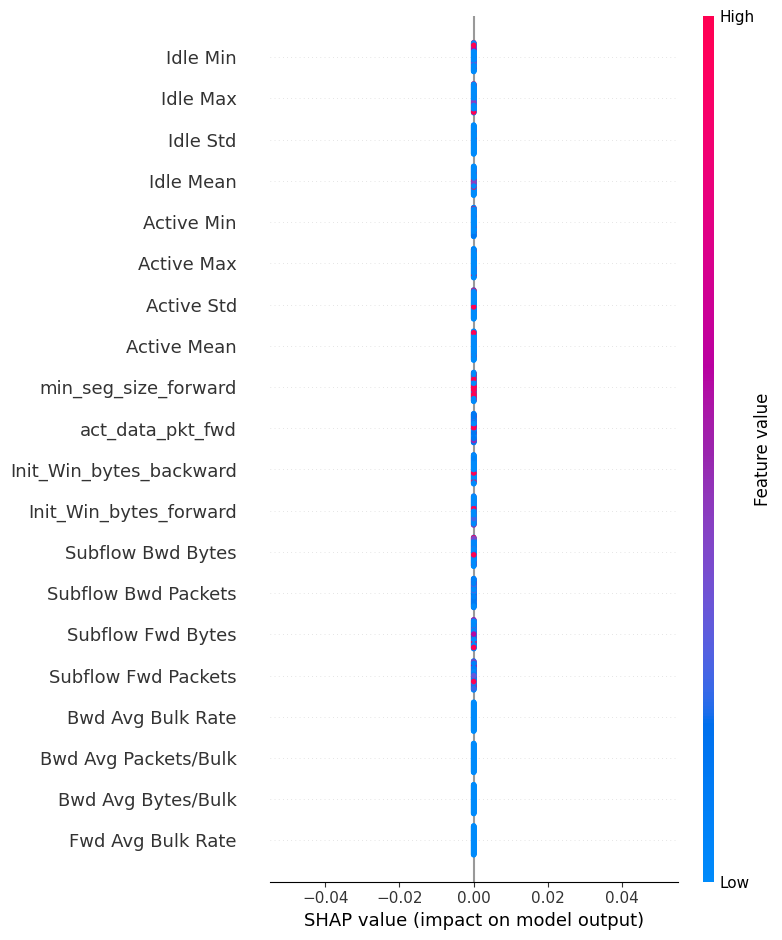

In [ ]:

explainer = shap.TreeExplainer(rf_model)

# Explain a small sample
X_sample = X_test[:100]

shap_values = explainer.shap_values(X_sample)

shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=X.columns
)


In [ ]:
# Inspect dataset
df.info()

# Count each type of network traffic
print("\nTraffic Label Distribution:")
print(df["Label"].value_counts())

<class 'pandas.core.frame.DataFrame'>
Index: 502650 entries, 0 to 529917
Data columns (total 80 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             502650 non-null  int64  
 1   Flow Duration                502650 non-null  int64  
 2   Total Fwd Packets            502650 non-null  int64  
 3   Total Backward Packets       502650 non-null  int64  
 4   Total Length of Fwd Packets  502650 non-null  int64  
 5   Total Length of Bwd Packets  502650 non-null  int64  
 6   Fwd Packet Length Max        502650 non-null  int64  
 7   Fwd Packet Length Min        502650 non-null  int64  
 8   Fwd Packet Length Mean       502650 non-null  float64
 9   Fwd Packet Length Std        502650 non-null  float64
 10  Bwd Packet Length Max        502650 non-null  int64  
 11  Bwd Packet Length Min        502650 non-null  int64  
 12  Bwd Packet Length Mean       502650 non-null  float64
 13  Bwd 

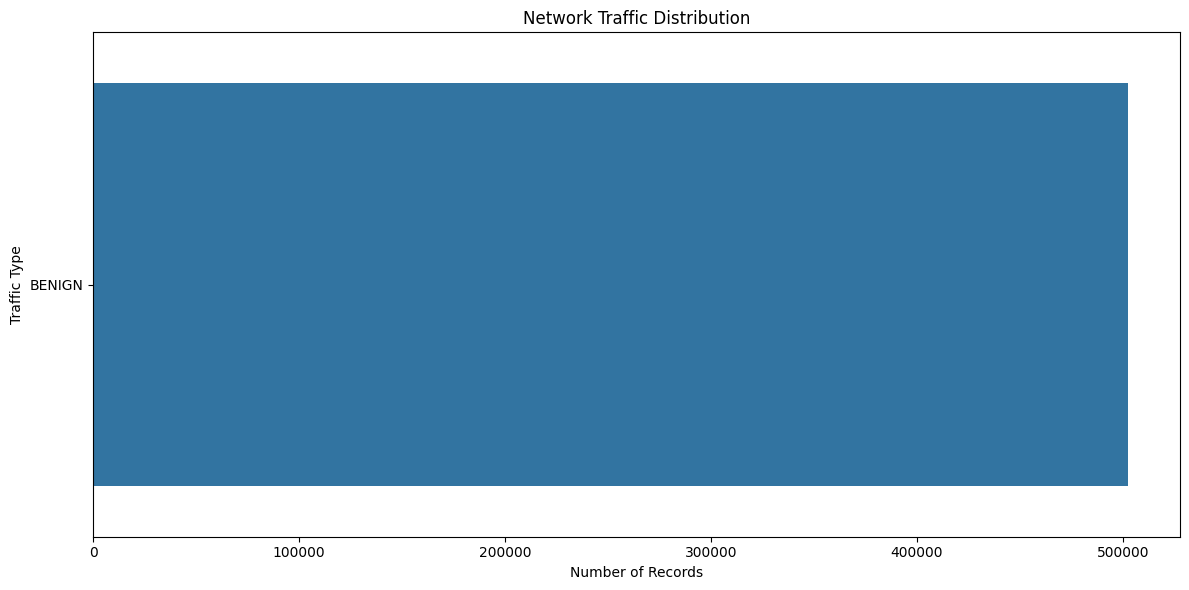

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Label",
    order=df["Label"].value_counts().index
)

plt.title("Network Traffic Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Traffic Type")
plt.tight_layout()
plt.show()

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/CICIDS2017"

print("Available CSV files:\n")

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

Available CSV files:

/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/content/drive/MyDrive/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:
print("Current DataFrame shape:", df.shape)

print("\nTraffic labels:")
print(df["Label"].value_counts(dropna=False))

print("\nLast 5 columns:")
print(df.columns[-5:].tolist())

Current DataFrame shape: (502650, 80)

Traffic labels:
Label
BENIGN    502650
Name: count, dtype: int64

Last 5 columns:
['Idle Std', 'Idle Max', 'Idle Min', 'Label', 'Target']


In [ ]:
import os
import pandas as pd

dataset_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCVE"

for file in os.listdir(dataset_path):
    if file.endswith(".csv"):

        file_path = os.path.join(dataset_path, file)

        # Read only the Label column
        temp = pd.read_csv(
            file_path,
            usecols=lambda col: col.strip() == "Label",
            low_memory=False
        )

        temp.columns = temp.columns.str.strip()
        temp["Label"] = temp["Label"].str.strip()

        print("\nFile:", file)
        print(temp["Label"].value_counts())


File: Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64

File: Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

File: Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    529918
Name: count, dtype: int64

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

File: Friday-WorkingHours-Aft

In [ ]:
import os
import pandas as pd

dataset_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCVE"

for file in os.listdir(dataset_path):

    if file.endswith(".csv"):

        file_path = os.path.join(dataset_path, file)

        temp = pd.read_csv(file_path, low_memory=False)

        temp.columns = temp.columns.str.strip()

        print("\nFile:", file)
        print(temp["Label"].value_counts())



File: Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64

File: Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

File: Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    529918
Name: count, dtype: int64

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

File: Friday-WorkingHours-Aft

In [ ]:
import os
import pandas as pd

dataset_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCVE"

# Store individual DataFrames
dataframes = []

# Read all CSV files
for file in os.listdir(dataset_path):

    if file.endswith(".csv"):

        file_path = os.path.join(dataset_path, file)

        print("Loading:", file)

        temp = pd.read_csv(file_path, low_memory=False)

        # Remove extra spaces from column names
        temp.columns = temp.columns.str.strip()

        # Remove extra spaces from labels
        temp["Label"] = temp["Label"].str.strip()

        dataframes.append(temp)

# Combine all DataFrames
combined_df = pd.concat(dataframes, ignore_index=True)

# Normalize the replacement character in Web Attack labels
combined_df["Label"] = combined_df["Label"].str.replace(
    "\ufffd", "-", regex=False
)

print("\nAll files combined successfully!")

print("Combined dataset shape:", combined_df.shape)

print("\nTraffic label distribution:")
print(combined_df["Label"].value_counts())

Loading: Wednesday-workingHours.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

All files combined successfully!
Combined dataset shape: (2830743, 79)

Traffic label distribution:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652


In [ ]:
import numpy as np

# Check missing values
missing = combined_df.isnull().sum()

print("Missing values:", missing.sum())
print("\nColumns with missing values:")
print(missing[missing > 0])

# Check infinite values
numeric_df = combined_df.select_dtypes(include=np.number)

infinite_count = np.isinf(numeric_df).sum().sum()

print("\nTotal infinite values:", infinite_count)

# Check duplicate records
duplicate_count = combined_df.duplicated().sum()

print("\nTotal duplicate records:", duplicate_count)

Missing values: 1358

Columns with missing values:
Flow Bytes/s    1358
dtype: int64

Total infinite values: 4376

Total duplicate records: 308381


In [ ]:
import numpy as np

# Count infinite values in each column
numeric_df = combined_df.select_dtypes(include=np.number)

infinity_counts = np.isinf(numeric_df).sum()

print("Infinite values by column:")
print(infinity_counts[infinity_counts > 0])

# Check duplicate records by traffic category
print("\nDuplicate records by label:")

duplicate_rows = combined_df[combined_df.duplicated(keep=False)]

print(duplicate_rows["Label"].value_counts())

# Check missing values by label
print("\nMissing Flow Bytes/s by label:")

print(
    combined_df.loc[
        combined_df["Flow Bytes/s"].isna(), "Label"
    ].value_counts()
)

NameError: name 'combined_df' is not defined

In [ ]:
import psutil

ram = psutil.virtual_memory()

print("Total RAM:", round(ram.total / (1024**3), 2), "GB")
print("Available RAM:", round(ram.available / (1024**3), 2), "GB")

Total RAM: 12.67 GB
Available RAM: 10.8 GB


In [ ]:
import os
import gc
import pandas as pd

dataset_path = "/content/drive/MyDrive/CICIDS2017/MachineLearningCVE"

output_path = "/content/drive/MyDrive/CICIDS2017/combined_CICIDS2017.csv"

# Get all CSV files
csv_files = sorted([
    f for f in os.listdir(dataset_path)
    if f.endswith(".csv")
])

# Use the first file to establish column names
first_file = os.path.join(dataset_path, csv_files[0])

columns = pd.read_csv(first_file, nrows=0).columns.str.strip().tolist()

# Process files one at a time
first_chunk = True

for file in csv_files:

    file_path = os.path.join(dataset_path, file)

    print("Processing:", file)

    for chunk in pd.read_csv(
        file_path,
        chunksize=100000,
        low_memory=False
    ):

        # Standardize column names
        chunk.columns = chunk.columns.str.strip()

        # Keep consistent column order
        chunk = chunk.reindex(columns=columns)

        # Clean labels
        chunk["Label"] = chunk["Label"].str.strip()
        chunk["Label"] = chunk["Label"].str.replace(
            "\ufffd", "-", regex=False
        )

        # Save each chunk directly to Drive
        chunk.to_csv(
            output_path,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False

        del chunk
        gc.collect()

print("\nAll files processed successfully!")
print("Saved at:", output_path)

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv

All files processed successfully!
Saved at: /content/drive/MyDrive/CICIDS2017/combined_CICIDS2017.csv


In [ ]:
import pandas as pd
import numpy as np
import os
import gc

file_path = "/content/drive/MyDrive/CICIDS2017/combined_CICIDS2017.csv"

chunksize = 100000
samples = []

print("Reading dataset in chunks...")

for chunk in pd.read_csv(file_path, chunksize=chunksize, low_memory=False):

    chunk.columns = chunk.columns.str.strip()
    chunk["Label"] = chunk["Label"].astype(str).str.strip()

    # Sample up to 1000 records per label per chunk
    for label, group in chunk.groupby("Label"):
        samples.append(group.sample(
            n=min(len(group), 1000),
            random_state=42
        ))

    del chunk
    gc.collect()

# Combine sampled records
model_df = pd.concat(samples, ignore_index=True)

# Limit each category to at most 10000 records
model_df = (
    model_df.groupby("Label", group_keys=False)
    .apply(lambda x: x.sample(
        n=min(len(x), 10000),
        random_state=42
    ))
    .reset_index(drop=True)
)

print("Sample created:", model_df.shape)
print("\nTraffic distribution:")
print(model_df["Label"].value_counts())

Reading dataset in chunks...
Sample created: (32708, 79)

Traffic distribution:
Label
BENIGN                        10000
DoS GoldenEye                  4006
PortScan                       3372
SSH-Patator                    3271
DoS Hulk                       3000
DoS slowloris                  2000
DDoS                           2000
Bot                            1322
FTP-Patator                    1017
DoS Slowhttptest               1000
Web Attack - Brute Force       1000
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64


/tmp/ipykernel_38509/3497787934.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


In [ ]:
# Remove unwanted spaces
model_df.columns = model_df.columns.str.strip()
model_df["Label"] = model_df["Label"].str.strip()

# Convert numeric columns
feature_cols = model_df.columns.drop("Label")

for col in feature_cols:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

# Replace infinite values with NaN
model_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove exact duplicate rows
before = len(model_df)
model_df.drop_duplicates(inplace=True)
print("Duplicates removed:", before - len(model_df))

# Remove rows where every feature is missing
model_df.dropna(subset=feature_cols, how="all", inplace=True)

# Fill missing numeric values with column medians
medians = model_df[feature_cols].median()
model_df[feature_cols] = model_df[feature_cols].fillna(medians)

# Remove any remaining invalid rows
# Fix: Convert Index to list before list concatenation
model_df.dropna(subset=list(feature_cols) + ["Label"], inplace=True)

model_df.reset_index(drop=True, inplace=True)

print("Shape after cleaning:", model_df.shape)
print("Remaining missing values:", model_df.isnull().sum().sum())
print("Remaining infinite values:",
      np.isinf(model_df.select_dtypes(include=np.number)).sum().sum())

Duplicates removed: 0
Shape after cleaning: (30208, 79)
Remaining missing values: 0
Remaining infinite values: 0


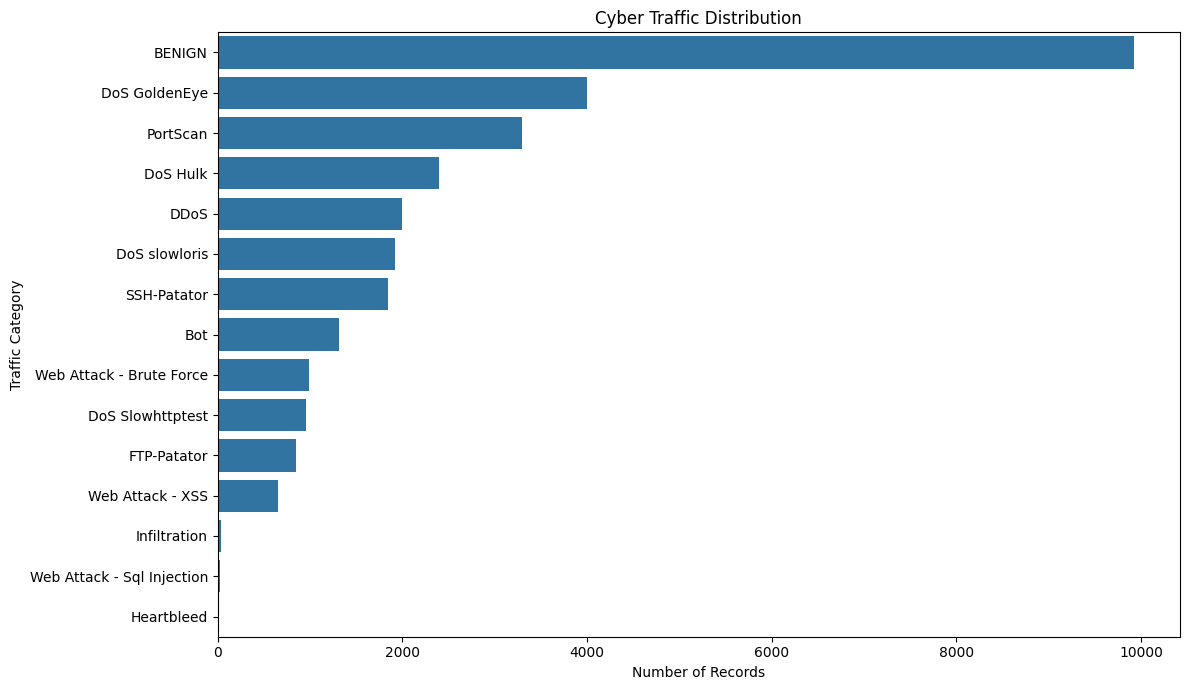

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Traffic distribution
plt.figure(figsize=(12, 7))

sns.countplot(
    data=model_df,
    y="Label",
    order=model_df["Label"].value_counts().index
)

plt.title("Cyber Traffic Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Traffic Category")
plt.tight_layout()
plt.show()

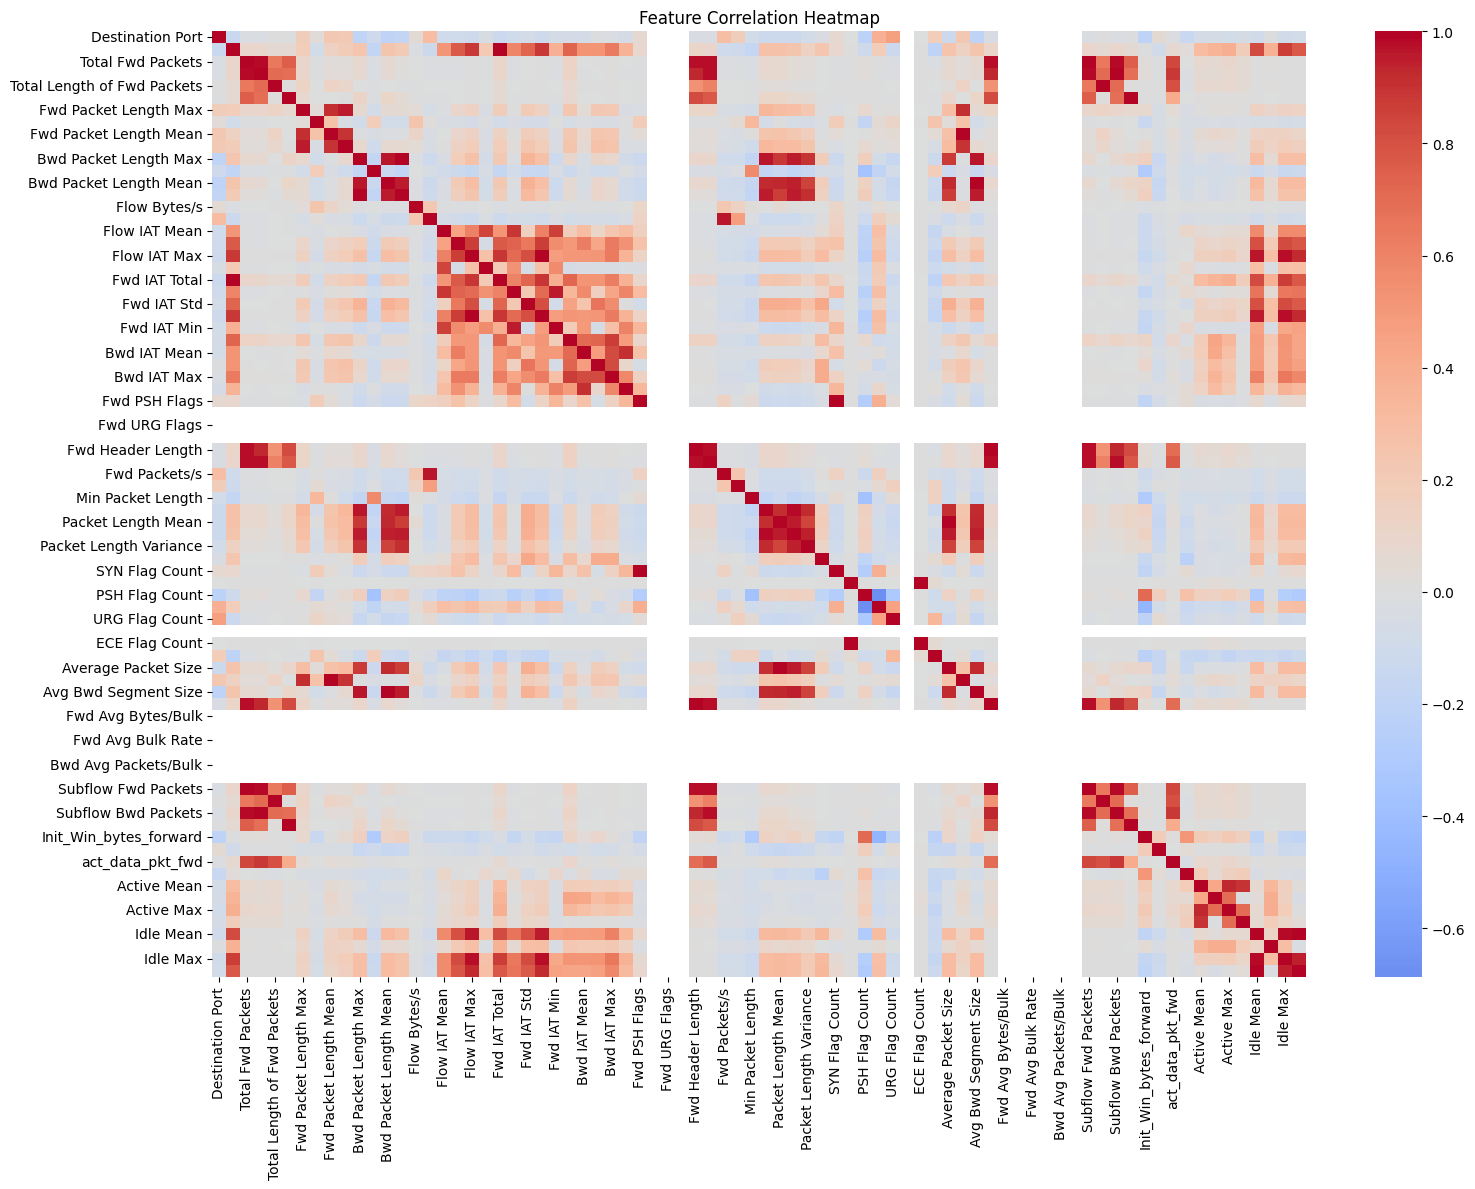

In [ ]:
# Feature correlation heatmap
plt.figure(figsize=(16, 12))

correlation = model_df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

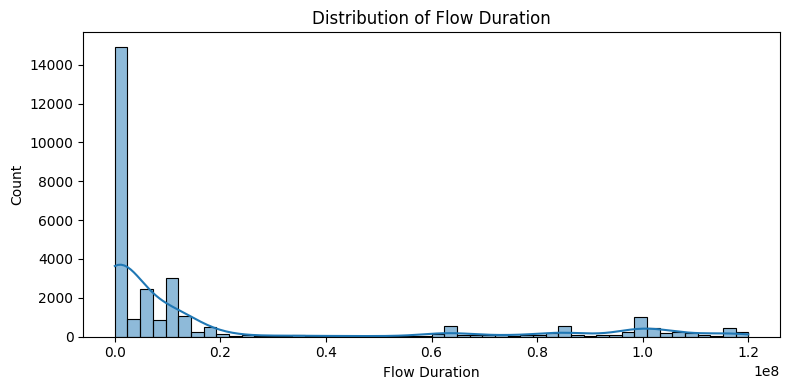

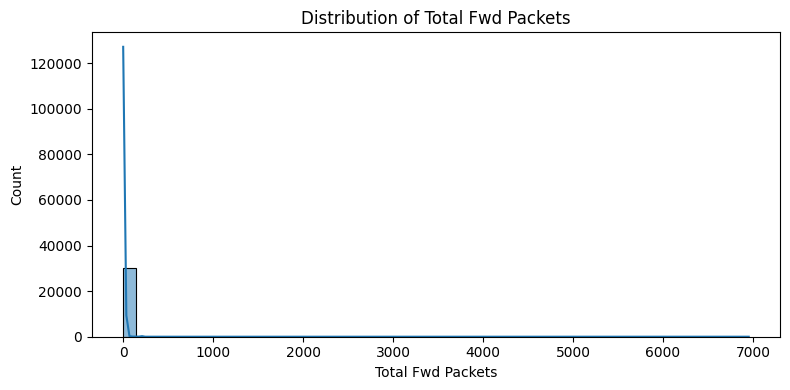

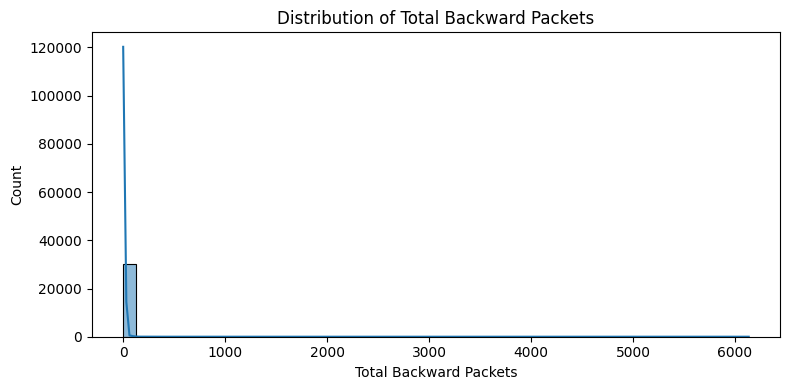

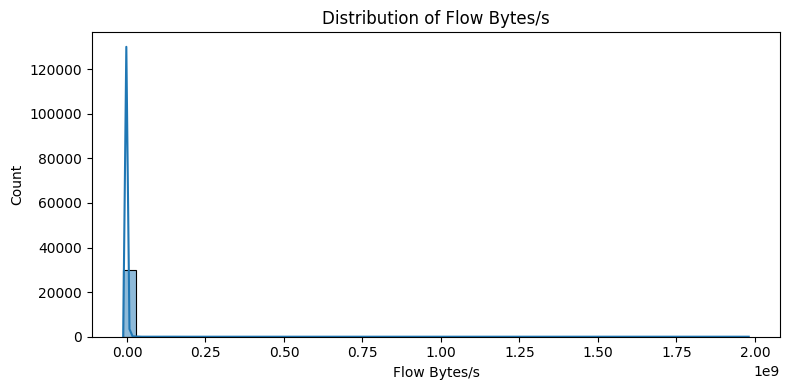

In [ ]:
# Distribution of selected network features
selected_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s"
]

for feature in selected_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(model_df[feature], bins=50, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Create binary target
model_df["Target"] = (
    model_df["Label"] != "BENIGN"
).astype(int)

# Separate features and target
X = model_df.drop(columns=["Label", "Target"])
y = model_df["Target"]

# Remove constant features
constant_cols = X.columns[X.nunique() <= 1]
X.drop(columns=constant_cols, inplace=True)

# Replace any remaining invalid values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values
X = X.fillna(X.median())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

Training shape: (24166, 68)
Testing shape: (6042, 68)

Training labels:
Target
1    16225
0     7941
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9973518702416418
Precision: 0.9982733103108041
Recall: 0.9977810650887574
F1 Score: 0.9980271270036991

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1986
           1       1.00      1.00      1.00      4056

    accuracy                           1.00      6042
   macro avg       1.00      1.00      1.00      6042
weighted avg       1.00      1.00      1.00      6042



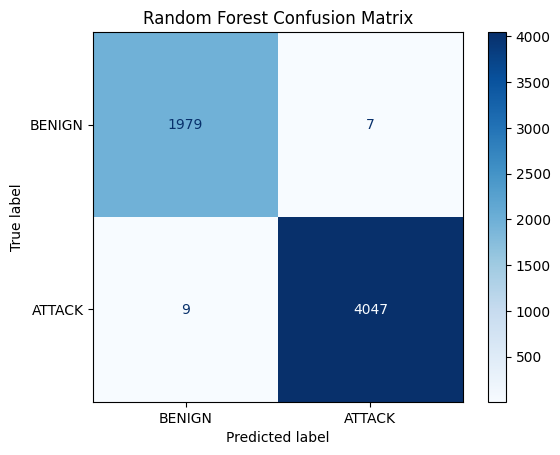

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
!pip install shap -q

In [ ]:
import shap

# Select a small sample for explanation
X_explain = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer(X_explain)

print("SHAP explanation generated!")

SHAP explanation generated!


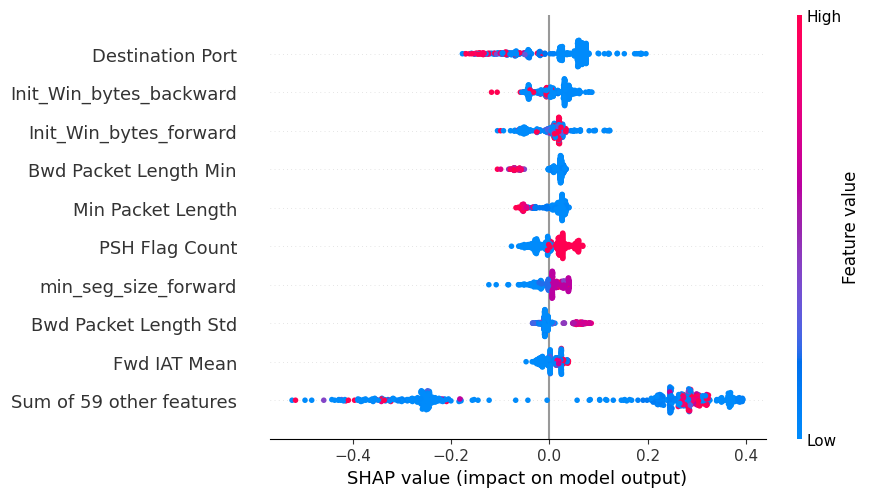

In [ ]:
# Global feature importance for the positive class (ATTACK)
shap.plots.beeswarm(shap_values[:, :, 1])

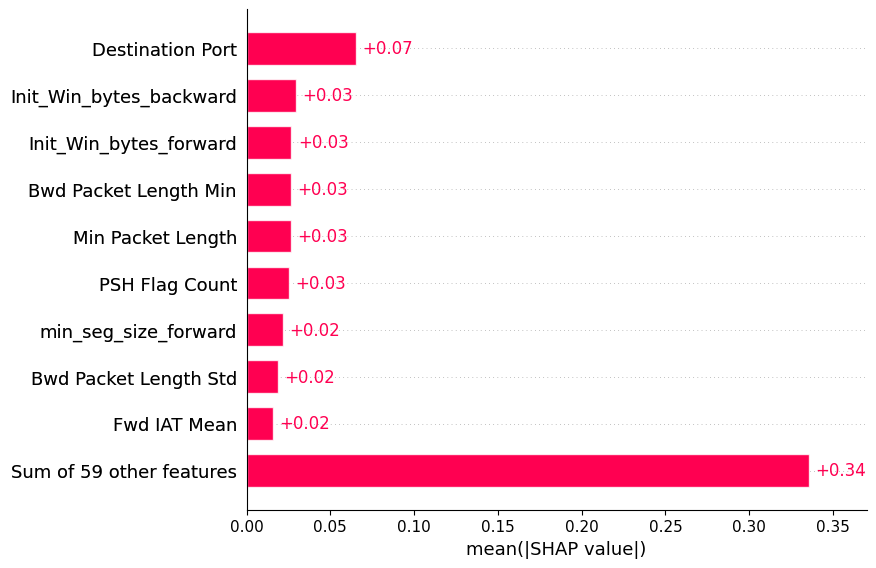

In [ ]:
# Feature importance bar plot for the positive class (ATTACK)
shap.plots.bar(shap_values[:, :, 1])

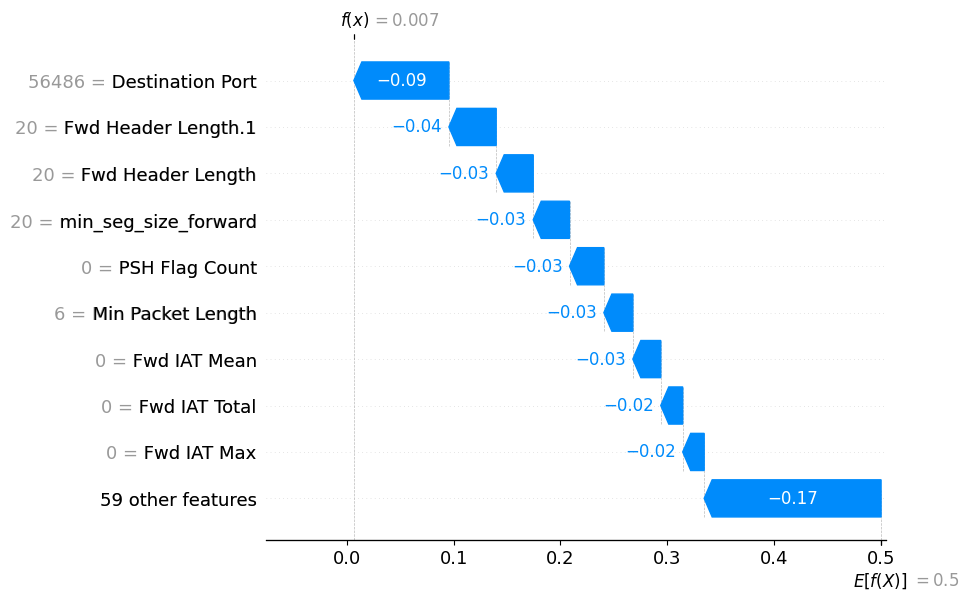

In [ ]:
# Explain an individual prediction
shap.plots.waterfall(shap_values[0, :, 1])

In [ ]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/CICIDS2017/random_forest_model.pkl"
)

joblib.dump(
    list(X.columns),
    "/content/drive/MyDrive/CICIDS2017/model_features.pkl"
)

print("Model and feature list saved successfully!")

Model and feature list saved successfully!


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/CICIDS2017/combined_CICIDS2017.csv"

# Read only column names, not the entire dataset
columns = pd.read_csv(file_path, nrows=0).columns.tolist()

print("Available columns:")
print(columns)

print("\nChecking network endpoint columns:")

for col in columns:
    if any(word in col.lower() for word in ["source", "destination", "ip address"]):
        print(col)

Available columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Coun

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

folder = "/content/drive/MyDrive/CICIDS2017"

print("Files in project folder:")
print(os.listdir(folder))

Files in project folder:
['MachineLearningCSV.zip', 'MachineLearningCVE', 'combined_CICIDS2017.csv', 'random_forest_model.pkl', 'model_features.pkl']


In [ ]:

import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/CICIDS2017/combined_CICIDS2017.csv"

# Load the dataset
df = pd.read_csv(file_path)

print("Original shape:", df.shape)

# Clean column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Fill missing numeric values with median
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# Create binary target
df["Target"] = (df["Label"].str.strip() != "BENIGN").astype(int)

print("\nCleaned shape:", df.shape)
print("\nTarget distribution:")
print(df["Target"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())


Original shape: (2830743, 79)

Cleaned shape: (2522362, 80)

Target distribution:
Target
0    2096484
1     425878
Name: count, dtype: int64

Missing values: 0


In [ ]:

# Create a balanced sample
gnn_df = (
    df.groupby("Target", group_keys=False)
      .sample(n=5000, random_state=42)
      .reset_index(drop=True)
)

# Select numeric features, excluding the target
feature_cols = gnn_df.select_dtypes(include=np.number).columns.tolist()
feature_cols.remove("Target")

# Save the GNN dataset to Google Drive
save_path = "/content/drive/MyDrive/CICIDS2017/gnn_sample.csv"
gnn_df.to_csv(save_path, index=False)

print("GNN sample shape:", gnn_df.shape)
print("\nTarget distribution:")
print(gnn_df["Target"].value_counts())

print("\nNumber of numeric features:", len(feature_cols))
print("\nSaved successfully at:", save_path)


GNN sample shape: (10000, 80)

Target distribution:
Target
0    5000
1    5000
Name: count, dtype: int64

Number of numeric features: 78

Saved successfully at: /content/drive/MyDrive/CICIDS2017/gnn_sample.csv


In [ ]:

from sklearn.preprocessing import StandardScaler

# Separate features and labels
X = gnn_df[feature_cols].copy()
y = gnn_df["Target"].copy()

# Replace any remaining infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values
X = X.fillna(X.median())

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)
print("\nMean of first 5 features:")
print(X_scaled.mean(axis=0)[:5])

print("\nStandard deviation of first 5 features:")
print(X_scaled.std(axis=0)[:5])


Scaled feature shape: (10000, 78)

Mean of first 5 features:
[ 0.00000000e+00 -4.54747351e-17 -5.68434189e-18  1.13686838e-17
 -5.68434189e-18]

Standard deviation of first 5 features:
[1. 1. 1. 1. 1.]


In [ ]:

from sklearn.neighbors import kneighbors_graph
import numpy as np

# Find the 5 nearest neighbors for each network flow
knn_graph = kneighbors_graph(
    X_scaled,
    n_neighbors=5,
    mode="connectivity",
    include_self=False
)

# Convert to a symmetric graph
adjacency = knn_graph.maximum(knn_graph.T)

# Extract graph edges
edge_index = np.array(adjacency.nonzero())

print("Number of nodes:", X_scaled.shape[0])
print("Number of edges:", edge_index.shape[1])
print("Edge index shape:", edge_index.shape)

# Check a few connections
print("\nFirst 10 edges:")
print(edge_index[:, :10])


Number of nodes: 10000
Number of edges: 66066
Edge index shape: (2, 66066)

First 10 edges:
[[   0    0    0    0    0    0    0    1    1    1]
 [3659  709  234 1674 3470 2842  150 2515 1148 1972]]


In [ ]:

!pip install torch-geometric


In [ ]:

import torch
import torch.nn.functional as F

from torch_geometric.data import Data

# Convert features and labels to PyTorch tensors
node_features = torch.tensor(X_scaled, dtype=torch.float)
node_labels = torch.tensor(y.values, dtype=torch.long)

# Convert graph edges to PyTorch tensor
edge_index_tensor = torch.tensor(edge_index, dtype=torch.long)

# Create PyTorch Geometric graph
data = Data(
    x=node_features,
    edge_index=edge_index_tensor,
    y=node_labels
)

print(data)
print("\nNumber of nodes:", data.num_nodes)
print("Number of edges:", data.num_edges)
print("Number of features:", data.num_node_features)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Data(x=[10000, 78], edge_index=[2, 66066], y=[10000])

Number of nodes: 10000
Number of edges: 66066
Number of features: 78


In [ ]:

from sklearn.model_selection import train_test_split
import numpy as np
import torch

# Get node indices
indices = np.arange(data.num_nodes)

# First split: 70% training, 30% remaining
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y.iloc[temp_idx]
)

# Convert indices to PyTorch tensors
train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
val_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)

train_mask[train_idx] = True
val_mask[val_idx] = True
test_mask[test_idx] = True

# Attach masks to graph
data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

print("Training nodes:", train_mask.sum().item())
print("Validation nodes:", val_mask.sum().item())
print("Testing nodes:", test_mask.sum().item())

print("\nTraining label distribution:")
print(torch.bincount(data.y[train_mask]))

print("\nValidation label distribution:")
print(torch.bincount(data.y[val_mask]))

print("\nTesting label distribution:")
print(torch.bincount(data.y[test_mask]))


Training nodes: 7000
Validation nodes: 1500
Testing nodes: 1500

Training label distribution:
tensor([3500, 3500])

Validation label distribution:
tensor([750, 750])

Testing label distribution:
tensor([750, 750])


In [ ]:

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(torch.nn.Module):
    def __init__(self, input_features, hidden_channels, num_classes):
        super(GCN, self).__init__()

        self.conv1 = GCNConv(input_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)

    def forward(self, x, edge_index):
        # First graph convolution
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        # Second graph convolution
        x = self.conv2(x, edge_index)

        return x

# Initialize model
model = GCN(
    input_features=data.num_node_features,
    hidden_channels=32,
    num_classes=2
)

print(model)
print("\nTotal trainable parameters:",
      sum(p.numel() for p in model.parameters()))


GCN(
  (conv1): GCNConv(78, 32)
  (conv2): GCNConv(32, 2)
)

Total trainable parameters: 2594


In [ ]:

import torch
import torch.nn.functional as F

# Optimizer and loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()

# Store training history
train_losses = []
val_losses = []
val_accuracies = []

# Training loop
for epoch in range(1, 101):

    model.train()
    optimizer.zero_grad()

    # Forward propagation
    out = model(data.x, data.edge_index)

    # Calculate training loss
    loss = criterion(out[data.train_mask], data.y[data.train_mask])

    # Backpropagation
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # Validation
    model.eval()
    with torch.no_grad():
        val_out = model(data.x, data.edge_index)
        val_loss = criterion(
            val_out[data.val_mask],
            data.y[data.val_mask]
        )

        val_pred = val_out[data.val_mask].argmax(dim=1)
        val_acc = (
            val_pred == data.y[data.val_mask]
        ).float().mean().item()

    val_losses.append(val_loss.item())
    val_accuracies.append(val_acc)

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_acc:.4f}"
        )


Epoch 010 | Train Loss: 0.2030 | Val Loss: 0.1842 | Val Accuracy: 0.9367
Epoch 020 | Train Loss: 0.1625 | Val Loss: 0.1554 | Val Accuracy: 0.9487
Epoch 030 | Train Loss: 0.1342 | Val Loss: 0.1308 | Val Accuracy: 0.9567
Epoch 040 | Train Loss: 0.1226 | Val Loss: 0.1126 | Val Accuracy: 0.9580
Epoch 050 | Train Loss: 0.1066 | Val Loss: 0.1058 | Val Accuracy: 0.9607
Epoch 060 | Train Loss: 0.1042 | Val Loss: 0.0981 | Val Accuracy: 0.9667
Epoch 070 | Train Loss: 0.0940 | Val Loss: 0.0934 | Val Accuracy: 0.9747
Epoch 080 | Train Loss: 0.0899 | Val Loss: 0.0891 | Val Accuracy: 0.9747
Epoch 090 | Train Loss: 0.0858 | Val Loss: 0.0865 | Val Accuracy: 0.9773
Epoch 100 | Train Loss: 0.0813 | Val Loss: 0.0846 | Val Accuracy: 0.9767


GCN TEST RESULTS
----------------
Accuracy : 0.974
Precision: 0.9634941329856584
Recall   : 0.9853333333333333
F1 Score : 0.974291364535267

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.96      0.97       750
      Attack       0.96      0.99      0.97       750

    accuracy                           0.97      1500
   macro avg       0.97      0.97      0.97      1500
weighted avg       0.97      0.97      0.97      1500



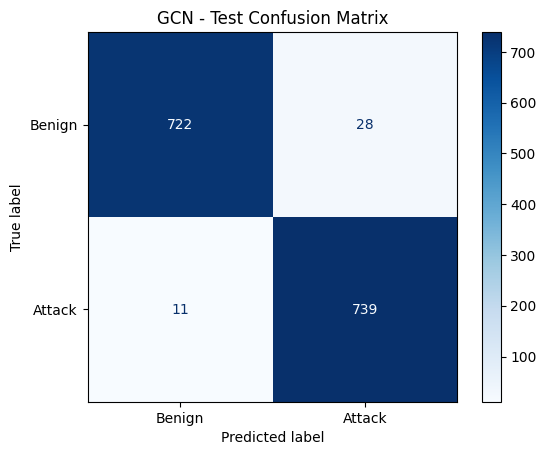


GCN model saved at: /content/drive/MyDrive/CICIDS2017/gcn_model.pth


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

# Evaluate model
model.eval()

with torch.no_grad():
    predictions = model(data.x, data.edge_index)
    test_predictions = predictions[data.test_mask].argmax(dim=1)
    test_actual = data.y[data.test_mask]

# Convert to NumPy
y_true = test_actual.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

# Calculate metrics
print("GCN TEST RESULTS")
print("----------------")
print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1 Score :", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Benign", "Attack"]
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
).plot(cmap="Blues")

plt.title("GCN - Test Confusion Matrix")
plt.show()

# Save trained model
model_path = "/content/drive/MyDrive/CICIDS2017/gcn_model.pth"
torch.save(model.state_dict(), model_path)

print("\nGCN model saved at:", model_path)


In [ ]:

from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.explain import ModelConfig
import matplotlib.pyplot as plt
import numpy as np

# Find a correctly predicted attack node in the test set
model.eval()

with torch.no_grad():
    all_predictions = model(data.x, data.edge_index).argmax(dim=1)

correct_attack_nodes = torch.where(
    data.test_mask &
    (data.y == 1) &
    (all_predictions == 1)
)[0]

node_idx = correct_attack_nodes[0].item()

print("Selected node:", node_idx)
print("Actual label:", data.y[node_idx].item())
print("Predicted label:", all_predictions[node_idx].item())

# Initialize GNNExplainer
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=200),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=ModelConfig(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

# Generate explanation
explanation = explainer(
    x=data.x,
    edge_index=data.edge_index,
    index=node_idx
)

print("\nExplanation generated!")
print("Node mask shape:", explanation.node_mask.shape)
print("Edge mask shape:", explanation.edge_mask.shape)


Selected node: 5011
Actual label: 1
Predicted label: 1

Explanation generated!
Node mask shape: torch.Size([10000, 78])
Edge mask shape: torch.Size([66066])


Top 15 Important Features:
               Feature  Importance
        FIN Flag Count    0.737664
 Bwd Packet Length Max    0.723102
     Max Packet Length    0.702936
          Flow IAT Std    0.701073
              Idle Min    0.672823
     Packet Length Std    0.652967
 Bwd Packet Length Std    0.645785
Packet Length Variance    0.637992
    Packet Length Mean    0.626915
           Bwd IAT Std    0.626759
   Average Packet Size    0.608755
             Idle Mean    0.604816
              Idle Max    0.536943
           Fwd IAT Max    0.486217
Init_Win_bytes_forward    0.418612


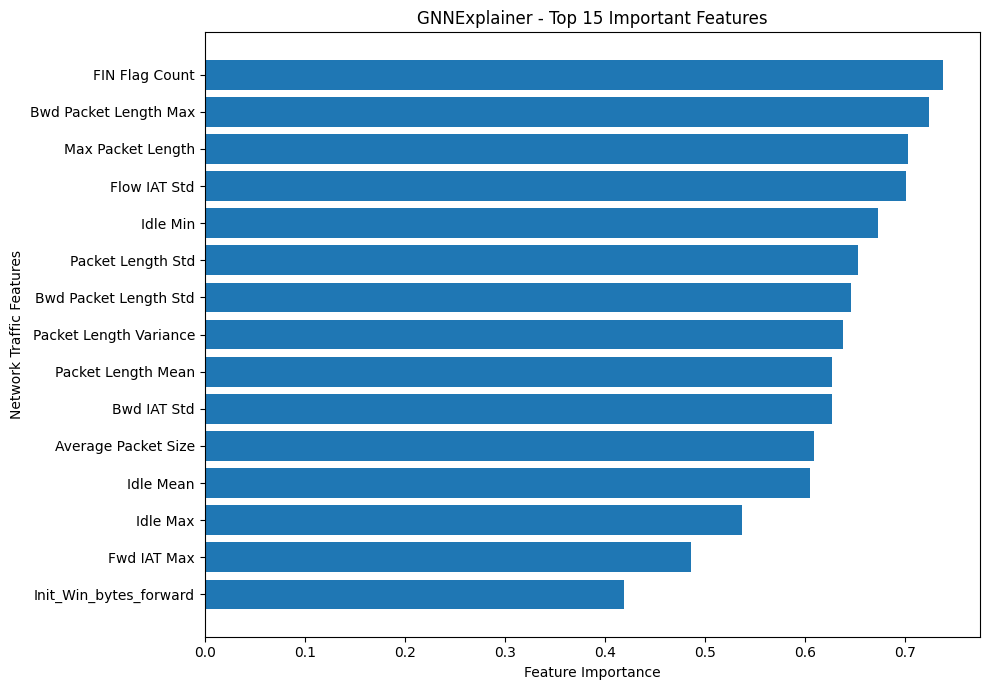

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract feature importance for selected node
node_importance = explanation.node_mask[
    node_idx
].detach().cpu().numpy()

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": node_importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
print(feature_importance.head(15).to_string(index=False))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Network Traffic Features")
plt.title("GNNExplainer - Top 15 Important Features")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

# Get edge importance scores
edge_scores = explanation.edge_mask.detach().cpu().numpy()

# Find edges connected to our selected node
edges = edge_index

incident_mask = (
    (edges[0] == node_idx) |
    (edges[1] == node_idx)
)

incident_positions = np.where(incident_mask)[0]

# Get neighboring nodes
neighbor_edges = edges[:, incident_positions]
neighbor_scores = edge_scores[incident_positions]

neighbor_df = pd.DataFrame({
    "Source_Node": neighbor_edges[0],
    "Destination_Node": neighbor_edges[1],
    "Edge_Importance": neighbor_scores
})

# Sort by importance
neighbor_df = neighbor_df.sort_values(
    by="Edge_Importance",
    ascending=False
)

print("Selected attack node:", node_idx)
print("Number of connected edges:", len(neighbor_df))

print("\nTop 15 Important Connections:")
print(neighbor_df.head(15).to_string(index=False))


Selected attack node: 5011
Number of connected edges: 10

Top 15 Important Connections:
 Source_Node  Destination_Node  Edge_Importance
        5011              6729         0.932016
        5011              5333         0.930421
        5011              9946         0.930250
        5011              6056         0.928890
        9946              5011         0.842661
        6729              5011         0.840951
        7616              5011         0.838335
        5333              5011         0.838229
        6056              5011         0.836276
        5011              7616         0.077595


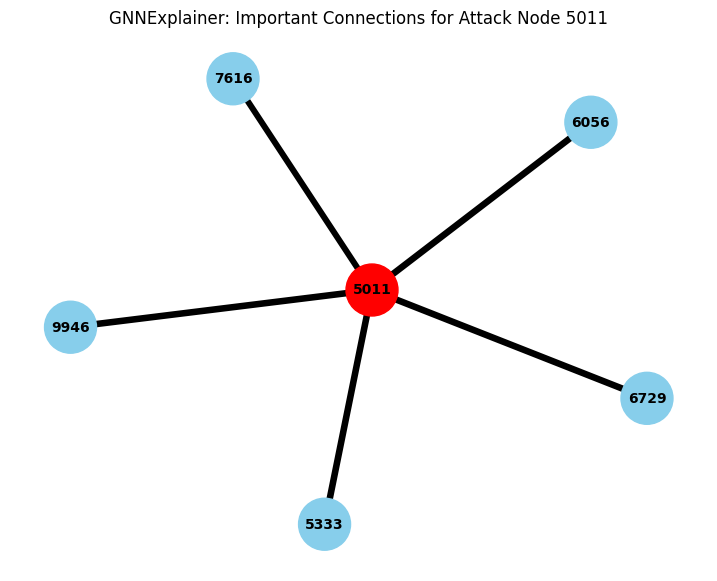

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt

# Create an undirected graph for visualization
G = nx.Graph()

G.add_node(node_idx)

# Add the five neighboring nodes
for _, row in neighbor_df.iterrows():
    source = int(row["Source_Node"])
    destination = int(row["Destination_Node"])

    score = float(row["Edge_Importance"])

    if G.has_edge(source, destination):
        G[source][destination]["importance"] = max(
            G[source][destination]["importance"], score
        )
    else:
        G.add_edge(
            source,
            destination,
            importance=score
        )

# Node colors: selected attack node vs neighbors
node_colors = [
    "red" if n == node_idx else "skyblue"
    for n in G.nodes()
]

# Edge widths based on importance
edge_widths = [
    1 + 4 * G[u][v]["importance"]
    for u, v in G.edges()
]

plt.figure(figsize=(9, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    node_size=1400,
    font_size=10,
    font_weight="bold",
    width=edge_widths,
    with_labels=True
)

plt.title("GNNExplainer: Important Connections for Attack Node 5011")
plt.axis("off")
plt.show()


In [ ]:

import os
import torch

# Create an explanation folder
explanation_folder = (
    "/content/drive/MyDrive/CICIDS2017/GNN_Explanations"
)
os.makedirs(explanation_folder, exist_ok=True)

# Save feature importance
feature_importance.to_csv(
    os.path.join(explanation_folder, "feature_importance.csv"),
    index=False
)

# Save important graph connections
neighbor_df.to_csv(
    os.path.join(explanation_folder, "edge_importance.csv"),
    index=False
)

# Save explanation masks
torch.save({
    "node_mask": explanation.node_mask.detach().cpu(),
    "edge_mask": explanation.edge_mask.detach().cpu(),
    "selected_node": node_idx
}, os.path.join(explanation_folder, "gnn_explanation.pt"))

print("GNN explanation results saved successfully!")

print("\nSaved files:")
print(os.listdir(explanation_folder))


GNN explanation results saved successfully!

Saved files:
['feature_importance.csv', 'edge_importance.csv', 'gnn_explanation.pt']


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import kneighbors_graph
from torch_geometric.data import Data
import numpy as np
import torch

# 1. Separate features and labels
X_raw = gnn_df[feature_cols].copy()
y_raw = gnn_df["Target"].to_numpy()

X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(X_raw.median())

# 2. Split BEFORE scaling and graph construction
indices = np.arange(len(gnn_df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y_raw
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y_raw[temp_idx]
)

# 3. Fit scaler only on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_raw.iloc[train_idx])
X_val = scaler.transform(X_raw.iloc[val_idx])
X_test = scaler.transform(X_raw.iloc[test_idx])

# 4. Construct separate similarity graphs
def create_graph_edges(features, offset):
    graph = kneighbors_graph(
        features,
        n_neighbors=5,
        mode="connectivity",
        include_self=False
    )

    graph = graph.maximum(graph.T)

    edges = np.array(graph.nonzero(), dtype=np.int64)

    return edges + offset

train_edges = create_graph_edges(X_train, 0)

val_edges = create_graph_edges(
    X_val, len(train_idx)
)

test_edges = create_graph_edges(
    X_test, len(train_idx) + len(val_idx)
)

# 5. Combine disconnected graphs
edge_index = np.concatenate(
    [train_edges, val_edges, test_edges],
    axis=1
)

# 6. Combine features and labels
X_all = np.vstack([X_train, X_val, X_test])

y_all = np.concatenate([
    y_raw[train_idx],
    y_raw[val_idx],
    y_raw[test_idx]
])

# 7. Create PyTorch Geometric data
data = Data(
    x=torch.tensor(X_all, dtype=torch.float),
    edge_index=torch.tensor(edge_index, dtype=torch.long),
    y=torch.tensor(y_all, dtype=torch.long)
)

# 8. Create masks
data.train_mask = torch.zeros(len(y_all), dtype=torch.bool)
data.val_mask = torch.zeros(len(y_all), dtype=torch.bool)
data.test_mask = torch.zeros(len(y_all), dtype=torch.bool)

data.train_mask[:len(train_idx)] = True

data.val_mask[
    len(train_idx):len(train_idx) + len(val_idx)
] = True

data.test_mask[
    len(train_idx) + len(val_idx):
] = True

print("Leakage-controlled graph prepared!")
print("Nodes:", data.num_nodes)
print("Edges:", data.num_edges)
print("Features:", data.num_node_features)

print("\nTraining:", data.train_mask.sum().item())
print("Validation:", data.val_mask.sum().item())
print("Testing:", data.test_mask.sum().item())


Leakage-controlled graph prepared!
Nodes: 10000
Edges: 66512
Features: 78

Training: 7000
Validation: 1500
Testing: 1500


In [ ]:

# Initialize a fresh GCN
model = GCN(
    input_features=data.num_node_features,
    hidden_channels=32,
    num_classes=2
)

# Optimizer and loss
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

criterion = torch.nn.CrossEntropyLoss()

# Training history
train_losses = []
val_losses = []
val_accuracies = []

# Train for 100 epochs
for epoch in range(1, 101):

    model.train()
    optimizer.zero_grad()

    out = model(data.x, data.edge_index)

    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # Validation
    model.eval()

    with torch.no_grad():
        val_out = model(data.x, data.edge_index)

        val_loss = criterion(
            val_out[data.val_mask],
            data.y[data.val_mask]
        )

        val_pred = val_out[data.val_mask].argmax(dim=1)

        val_acc = (
            val_pred == data.y[data.val_mask]
        ).float().mean().item()

    val_losses.append(val_loss.item())
    val_accuracies.append(val_acc)

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_acc:.4f}"
        )


Epoch 010 | Train Loss: 0.2153 | Val Loss: 0.2137 | Val Accuracy: 0.9353
Epoch 020 | Train Loss: 0.1793 | Val Loss: 0.1994 | Val Accuracy: 0.9453
Epoch 030 | Train Loss: 0.1538 | Val Loss: 0.1737 | Val Accuracy: 0.9473
Epoch 040 | Train Loss: 0.1300 | Val Loss: 0.1554 | Val Accuracy: 0.9513
Epoch 050 | Train Loss: 0.1213 | Val Loss: 0.1511 | Val Accuracy: 0.9520
Epoch 060 | Train Loss: 0.1163 | Val Loss: 0.1458 | Val Accuracy: 0.9513
Epoch 070 | Train Loss: 0.1097 | Val Loss: 0.1422 | Val Accuracy: 0.9513
Epoch 080 | Train Loss: 0.1045 | Val Loss: 0.1393 | Val Accuracy: 0.9527
Epoch 090 | Train Loss: 0.0989 | Val Loss: 0.1355 | Val Accuracy: 0.9587
Epoch 100 | Train Loss: 0.0973 | Val Loss: 0.1341 | Val Accuracy: 0.9560


LEAKAGE-CONTROLLED GCN TEST RESULTS
-----------------------------------
Accuracy : 0.9613333333333334
Precision: 0.9552631578947368
Recall   : 0.968
F1 Score : 0.9615894039735099

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.95      0.96       750
      Attack       0.96      0.97      0.96       750

    accuracy                           0.96      1500
   macro avg       0.96      0.96      0.96      1500
weighted avg       0.96      0.96      0.96      1500



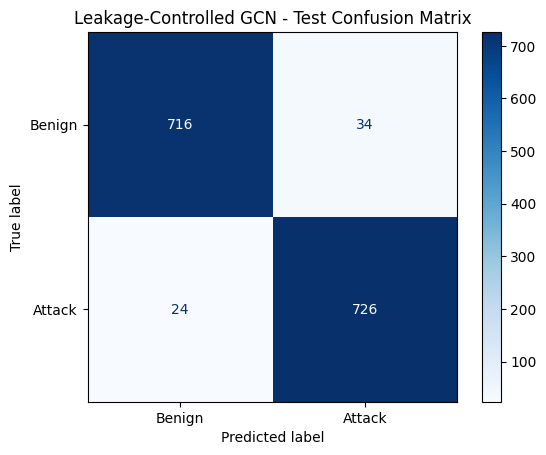


Corrected GCN model saved: /content/drive/MyDrive/CICIDS2017/gcn_model_corrected.pth


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import torch

model.eval()

with torch.no_grad():
    predictions = model(data.x, data.edge_index)
    test_predictions = predictions[data.test_mask].argmax(dim=1)
    test_actual = data.y[data.test_mask]

y_true = test_actual.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

print("LEAKAGE-CONTROLLED GCN TEST RESULTS")
print("-----------------------------------")

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1 Score :", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Benign", "Attack"]
))

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
).plot(cmap="Blues")

plt.title("Leakage-Controlled GCN - Test Confusion Matrix")
plt.show()

# Save corrected model
model_path = "/content/drive/MyDrive/CICIDS2017/gcn_model_corrected.pth"
torch.save(model.state_dict(), model_path)

print("\nCorrected GCN model saved:", model_path)


In [ ]:

from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.explain import ModelConfig
import torch
import os
import pandas as pd
import numpy as np

# Find correctly predicted attacks in the test set
model.eval()

with torch.no_grad():
    all_predictions = model(data.x, data.edge_index).argmax(dim=1)

correct_attack_nodes = torch.where(
    data.test_mask &
    (data.y == 1) &
    (all_predictions == 1)
)[0]

node_idx = correct_attack_nodes[0].item()

print("Selected test node:", node_idx)
print("Actual label:", data.y[node_idx].item())
print("Predicted label:", all_predictions[node_idx].item())

# Configure GNNExplainer
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=200),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=ModelConfig(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

# Generate explanation using corrected model and graph
explanation = explainer(
    x=data.x,
    edge_index=data.edge_index,
    index=node_idx
)

print("\nCorrected GNN explanation generated!")
print("Node mask shape:", explanation.node_mask.shape)
print("Edge mask shape:", explanation.edge_mask.shape)

# Save corrected explanation
folder = "/content/drive/MyDrive/CICIDS2017/GNN_Explanations"

torch.save({
    "node_mask": explanation.node_mask.detach().cpu(),
    "edge_mask": explanation.edge_mask.detach().cpu(),
    "selected_node": node_idx
}, os.path.join(folder, "corrected_gnn_explanation.pt"))

print("\nCorrected explanation saved!")


Selected test node: 8502
Actual label: 1
Predicted label: 1

Corrected GNN explanation generated!
Node mask shape: torch.Size([10000, 78])
Edge mask shape: torch.Size([66512])

Corrected explanation saved!


TOP 15 FEATURES - CORRECTED GNN
               Feature  Importance
             Idle Mean    0.706006
        FIN Flag Count    0.652521
 Bwd Packet Length Max    0.648849
           Fwd IAT Std    0.638355
          Flow IAT Std    0.612685
    Packet Length Mean    0.601692
Init_Win_bytes_forward    0.594042
           Fwd IAT Max    0.573997
          Flow IAT Max    0.567572
           Bwd IAT Std    0.561369
              Idle Max    0.555781
  Avg Bwd Segment Size    0.554650
 Bwd Packet Length Min    0.515393
     Packet Length Std    0.495983
         Flow IAT Mean    0.444438


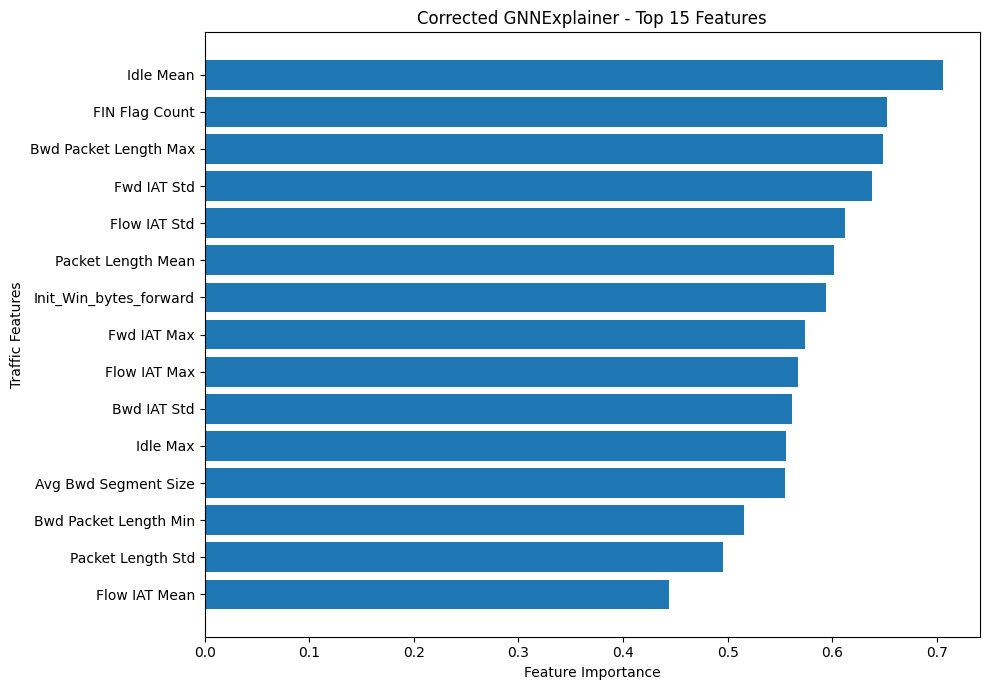


Feature importance saved successfully!


In [ ]:

# Extract importance scores for the selected test node
node_importance = explanation.node_mask[
    node_idx
].detach().cpu().numpy()

# Create feature importance table
corrected_feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": node_importance
})

corrected_feature_importance = (
    corrected_feature_importance
    .sort_values("Importance", ascending=False)
)

# Display top 15
print("TOP 15 FEATURES - CORRECTED GNN")
print(corrected_feature_importance.head(15).to_string(index=False))

# Visualize
top_features = corrected_feature_importance.head(15).sort_values(
    "Importance"
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Traffic Features")
plt.title("Corrected GNNExplainer - Top 15 Features")
plt.tight_layout()
plt.show()

# Save results
folder = "/content/drive/MyDrive/CICIDS2017/GNN_Explanations"

corrected_feature_importance.to_csv(
    os.path.join(folder, "corrected_feature_importance.csv"),
    index=False
)

print("\nFeature importance saved successfully!")


In [ ]:
# Extract edge importance scores
edge_importance = explanation.edge_mask.detach().cpu().numpy()

# Get the graph connections
# Fix: edge_index is already a numpy array, no need to call .detach().cpu().numpy()
edges = edge_index

# Find edges connected to the selected node
connected_edges = []

for i in range(edges.shape[1]):
    source = edges[0, i]
    target = edges[1, i]

    if source == node_idx or target == node_idx:
        connected_edges.append({
            "Source Node": source,
            "Neighbour Node": target if source == node_idx else source,
            "Importance": edge_importance[i]
        })

# Convert to DataFrame
edge_df = pd.DataFrame(connected_edges)

# Sort by importance
edge_df = edge_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("IMPORTANT NEIGHBOURING FLOWS")
print(edge_df.head(15).to_string(index=False))

# Save results
folder = "/content/drive/MyDrive/CICIDS2017/GNN_Explanations"

edge_df.to_csv(
    os.path.join(folder, "corrected_edge_importance.csv"),
    index=False
)

print("\nEdge importance saved successfully!")

IMPORTANT NEIGHBOURING FLOWS
 Source Node  Neighbour Node  Importance
        8502            9537    0.932389
        8502            8665    0.929581
        8502            9441    0.928879
        8502            8729    0.928775
        8502            9536    0.925759
        8502            8727    0.925572
        8502            8898    0.925394
        8502            9550    0.920727
        9537            9537    0.837782
        8729            8729    0.772980
        9441            9441    0.768505
        8665            8665    0.767743
        8898            8898    0.766511
        8727            8727    0.765778
        9536            9536    0.747718

Edge importance saved successfully!


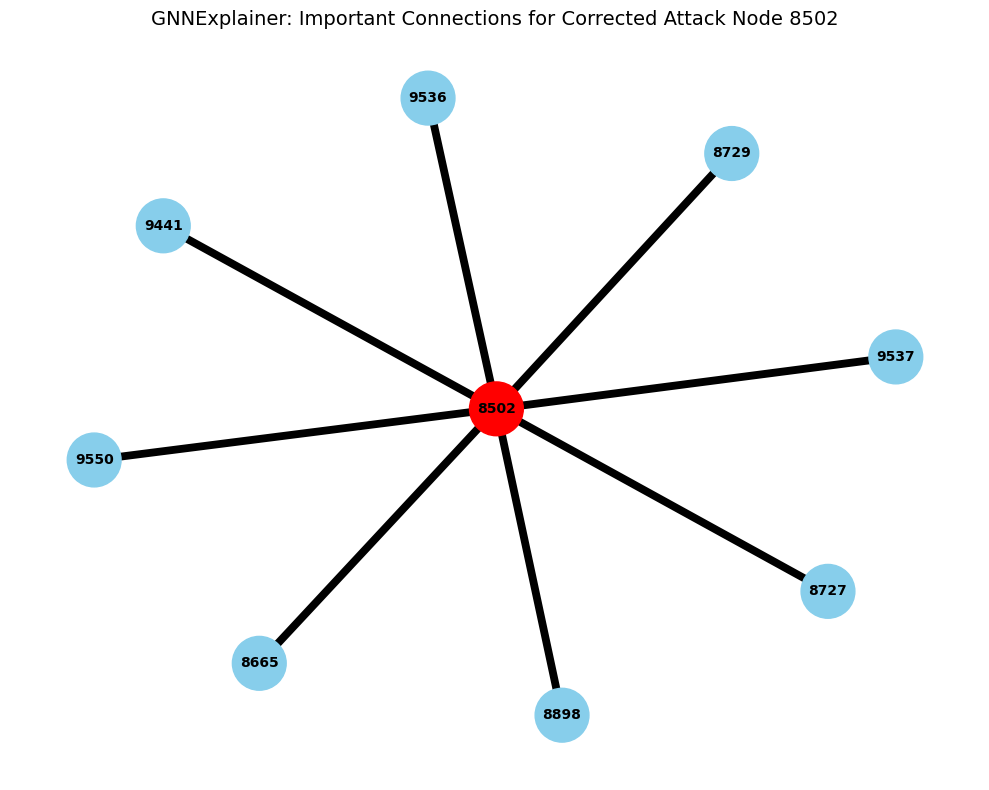

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create an undirected graph for visualization of Node 8502 and its neighbors
G = nx.Graph()
G.add_node(node_idx)

# Populate graph with top connections
for _, row in edge_df.head(15).iterrows():
    source = int(row["Source Node"])
    neighbor = int(row["Neighbour Node"])
    score = float(row["Importance"])

    # Avoid adding trivial self-loops to the spring layout visualization
    if source == neighbor:
        continue

    if G.has_edge(source, neighbor):
        G[source][neighbor]["importance"] = max(G[source][neighbor]["importance"], score)
    else:
        G.add_edge(source, neighbor, importance=score)

# Node colors: target attack node (red) vs neighbors (skyblue)
node_colors = ["red" if n == node_idx else "skyblue" for n in G.nodes()]

# Scale edge widths based on importance scores
edge_widths = [1 + 5 * G[u][v]["importance"] for u, v in G.edges()]

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    node_size=1500,
    font_size=10,
    font_weight="bold",
    width=edge_widths,
    with_labels=True
)

plt.title(f"GNNExplainer: Important Connections for Corrected Attack Node {node_idx}", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Get edge indices and importance scores
# Fix: edge_index is already a numpy array, no need to call .detach().cpu().numpy()
edge_index_np = edge_index
edge_scores = explanation.edge_mask.detach().cpu().numpy()

# Find edges connected to the selected node
source = edge_index_np[0]
target = edge_index_np[1]

incident_mask = (
    (source == node_idx) | (target == node_idx)
) & (source != target)

# Extract connected edges
neighbour_edges = pd.DataFrame({
    "Source Node": source[incident_mask],
    "Neighbour Node": target[incident_mask],
    "Importance": edge_scores[incident_mask]
})

# Keep only edges originating from node 8502
neighbour_edges = neighbour_edges[
    neighbour_edges["Source Node"] == node_idx
]

neighbour_edges = neighbour_edges.sort_values(
    "Importance", ascending=False
)

print("CORRECTED IMPORTANT NEIGHBOURING FLOWS")
print(neighbour_edges.to_string(index=False))

# Save the corrected results
neighbour_edges.to_csv(
    os.path.join(folder, "corrected_edge_importance.csv"),
    index=False
)

print("\nCorrected edge importance saved!")

CORRECTED IMPORTANT NEIGHBOURING FLOWS
 Source Node  Neighbour Node  Importance
        8502            9537    0.932389
        8502            8665    0.929581
        8502            9441    0.928879
        8502            8729    0.928775
        8502            9536    0.925759
        8502            8727    0.925572
        8502            8898    0.925394
        8502            9550    0.920727

Corrected edge importance saved!


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib
import os

# Prepare features and target
X_rf = gnn_df[feature_cols]
y_rf = gnn_df["Target"]

# Train Random Forest using the GNN training split
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_rf.iloc[train_idx], y_rf.iloc[train_idx])

# Predict on the same test split used by GCN
rf_predictions = rf_model.predict(X_rf.iloc[test_idx])
y_test_rf = y_rf.iloc[test_idx]

# Evaluate
print("RANDOM FOREST — TEST RESULTS")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test_rf, rf_predictions))
print("Precision:", precision_score(y_test_rf, rf_predictions))
print("Recall   :", recall_score(y_test_rf, rf_predictions))
print("F1-score :", f1_score(y_test_rf, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_rf,
    rf_predictions,
    target_names=["Benign", "Attack"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_rf, rf_predictions))

# Save model
save_path = "/content/drive/MyDrive/CICIDS2017/random_forest_comparison.pkl"
joblib.dump(rf_model, save_path)

print("\nRandom Forest model saved!")

RANDOM FOREST — TEST RESULTS
----------------------------------------
Accuracy : 0.9966666666666667
Precision: 1.0
Recall   : 0.9933333333333333
F1-score : 0.9966555183946488

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       750
      Attack       1.00      0.99      1.00       750

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500

Confusion Matrix:
[[750   0]
 [  5 745]]

Random Forest model saved!


TOP 15 FEATURES — RANDOM FOREST + SHAP
                    Feature  Importance
      Bwd Packet Length Std    0.035055
          Packet Length Std    0.034922
     Packet Length Variance    0.031670
          Max Packet Length    0.031311
     Bwd Packet Length Mean    0.028996
        Average Packet Size    0.027208
      Bwd Packet Length Max    0.025450
           Destination Port    0.024195
Total Length of Bwd Packets    0.019514
       Avg Bwd Segment Size    0.018862
      Fwd Packet Length Max    0.016529
         Packet Length Mean    0.016064
     Fwd Packet Length Mean    0.015962
     Init_Win_bytes_forward    0.015160
       Avg Fwd Segment Size    0.014897


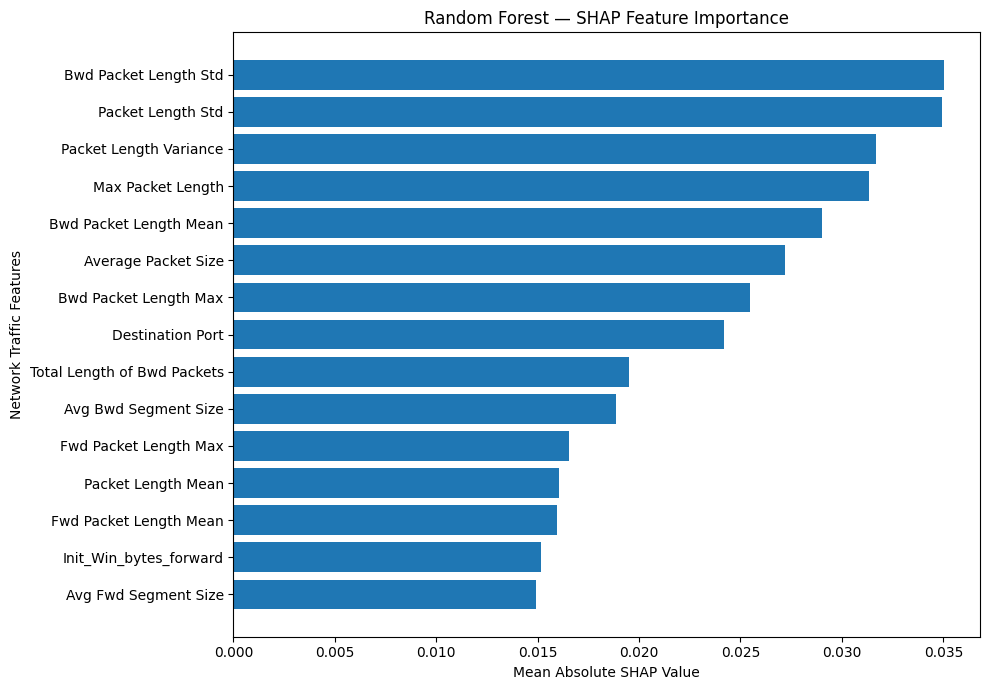


SHAP feature importance saved successfully!


In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Use the same test data
X_test_rf = X_rf.iloc[test_idx]

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_rf)

# Extract Attack-class SHAP values
if isinstance(shap_values, list):
    attack_shap = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    if shap_values.shape[-1] == 2:
        attack_shap = shap_values[:, :, 1]
    elif shap_values.shape[0] == 2:
        attack_shap = shap_values[1]

else:
    attack_shap = shap_values

# Calculate global feature importance
shap_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": np.abs(attack_shap).mean(axis=0)
}).sort_values("Importance", ascending=False)

print("TOP 15 FEATURES — RANDOM FOREST + SHAP")
print(shap_importance.head(15).to_string(index=False))

# Visualize top 15 features
top_features = shap_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Network Traffic Features")
plt.title("Random Forest — SHAP Feature Importance")
plt.tight_layout()
plt.show()

# Save results
folder = "/content/drive/MyDrive/CICIDS2017/GNN_Explanations"

shap_importance.to_csv(
    os.path.join(folder, "random_forest_shap_importance.csv"),
    index=False
)

print("\nSHAP feature importance saved successfully!")

In [ ]:
# Rank features from both explainability methods
rf_ranked = shap_importance.copy()
rf_ranked["RF Rank"] = range(1, len(rf_ranked) + 1)

gnn_ranked = corrected_feature_importance.copy()
gnn_ranked["GNN Rank"] = range(1, len(gnn_ranked) + 1)

# Select top 15 from each
rf_top15 = rf_ranked.head(15)
gnn_top15 = gnn_ranked.head(15)

# Find common features
comparison = pd.merge(
    rf_top15[["Feature", "RF Rank", "Importance"]],
    gnn_top15[["Feature", "GNN Rank", "Importance"]],
    on="Feature",
    how="outer",
    suffixes=("_SHAP", "_GNN")
)

comparison["Present in Both"] = (
    comparison["RF Rank"].notna() &
    comparison["GNN Rank"].notna()
)

comparison = comparison.sort_values(
    "Present in Both",
    ascending=False
)

print("SHAP vs GNNEXPLAINER — FEATURE COMPARISON")
print(comparison.to_string(index=False))

common_features = comparison[
    comparison["Present in Both"]
]

print("\nCOMMON TOP FEATURES:", len(common_features))
print(common_features["Feature"].tolist())

# Save comparison
comparison.to_csv(
    os.path.join(folder, "shap_gnn_feature_comparison.csv"),
    index=False
)

print("\nComparison saved successfully!")

SHAP vs GNNEXPLAINER — FEATURE COMPARISON
                    Feature  RF Rank  Importance_SHAP  GNN Rank  Importance_GNN  Present in Both
          Packet Length Std      2.0         0.034922      14.0        0.495983             True
      Bwd Packet Length Max      7.0         0.025450       3.0        0.648849             True
         Packet Length Mean     12.0         0.016064       6.0        0.601692             True
     Init_Win_bytes_forward     14.0         0.015160       7.0        0.594042             True
       Avg Bwd Segment Size     10.0         0.018862      12.0        0.554650             True
        Average Packet Size      6.0         0.027208       NaN             NaN            False
                Fwd IAT Std      NaN              NaN       4.0        0.638355            False
     Packet Length Variance      3.0         0.031670       NaN             NaN            False
          Max Packet Length      4.0         0.031311       NaN             NaN      

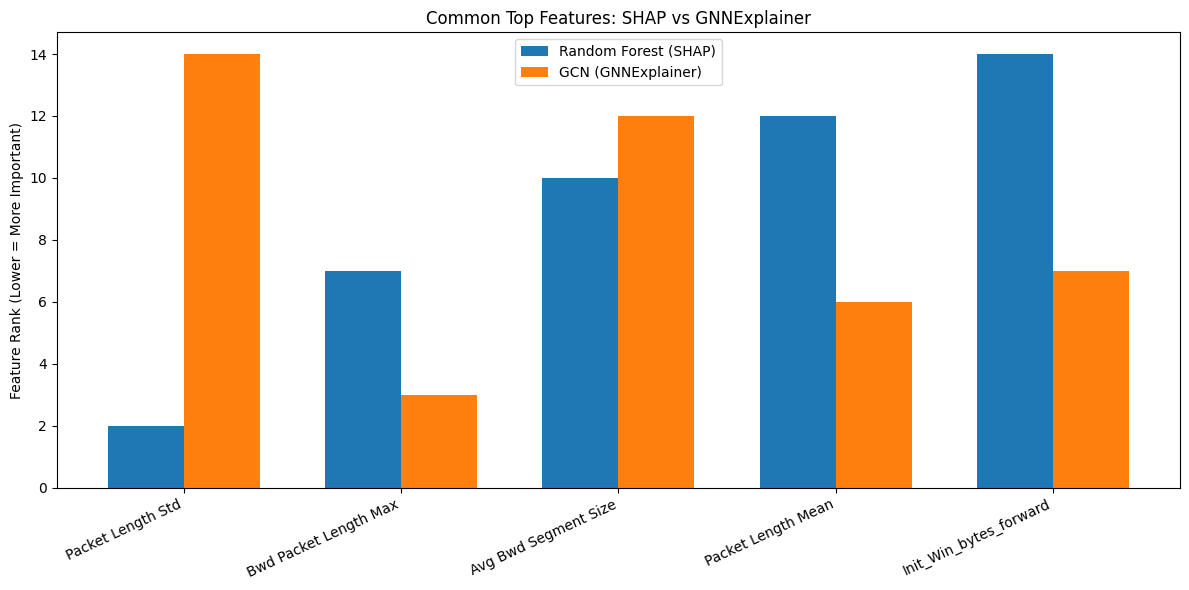

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

common = comparison[
    comparison["Present in Both"]
].copy()

common = common.sort_values("RF Rank", ascending=True)

x = np.arange(len(common))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    common["RF Rank"],
    width,
    label="Random Forest (SHAP)"
)

plt.bar(
    x + width/2,
    common["GNN Rank"],
    width,
    label="GCN (GNNExplainer)"
)

plt.xticks(
    x,
    common["Feature"],
    rotation=25,
    ha="right"
)

plt.ylabel("Feature Rank (Lower = More Important)")
plt.title("Common Top Features: SHAP vs GNNExplainer")
plt.legend()
plt.tight_layout()
plt.show()

# Save the graph
plt.savefig(
    os.path.join(folder, "common_feature_rank_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

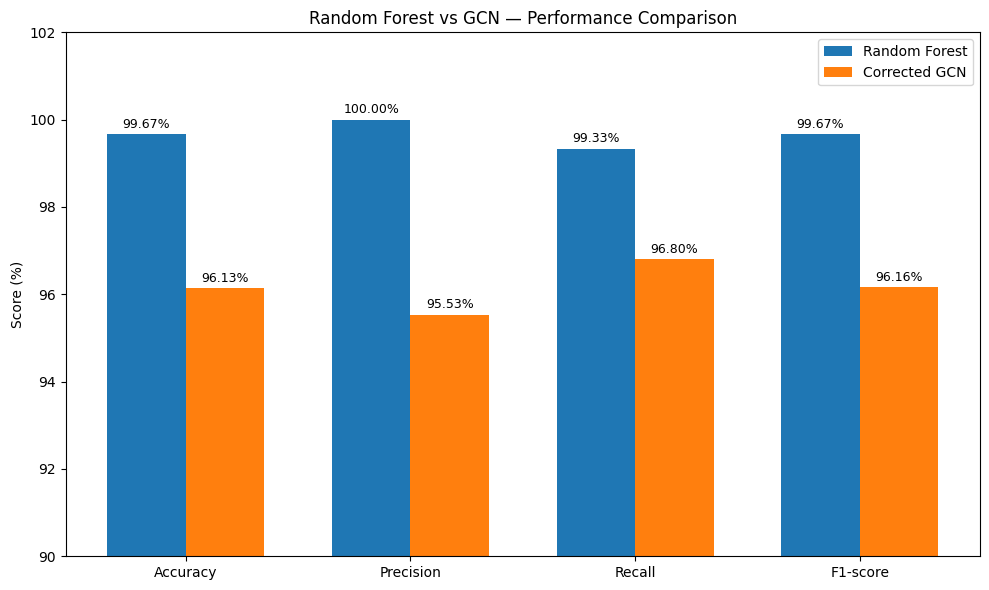

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Random Forest", "Corrected GCN"]

metrics = {
    "Accuracy": [0.996667, 0.961333],
    "Precision": [1.000000, 0.955263],
    "Recall": [0.993333, 0.968000],
    "F1-score": [0.996656, 0.961589]
}

x = np.arange(len(metrics))
width = 0.35

rf_scores = [metrics[m][0] * 100 for m in metrics]
gcn_scores = [metrics[m][1] * 100 for m in metrics]

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, rf_scores, width, label="Random Forest")
plt.bar(x + width/2, gcn_scores, width, label="Corrected GCN")

plt.xticks(x, list(metrics.keys()))
plt.ylabel("Score (%)")
plt.ylim(90, 102)
plt.title("Random Forest vs GCN — Performance Comparison")
plt.legend()

for i, value in enumerate(rf_scores):
    plt.text(i - width/2, value + 0.15, f"{value:.2f}%",
             ha="center", fontsize=9)

for i, value in enumerate(gcn_scores):
    plt.text(i + width/2, value + 0.15, f"{value:.2f}%",
             ha="center", fontsize=9)

plt.tight_layout()

plt.savefig(
    os.path.join(folder, "model_performance_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
final_results = pd.DataFrame({
    "Model": ["Random Forest", "Corrected GCN"],
    "Accuracy": [0.996667, 0.961333],
    "Precision": [1.000000, 0.955263],
    "Recall": [0.993333, 0.968000],
    "F1 Score": [0.996656, 0.961589]
})

print(final_results.to_string(index=False))

final_results.to_csv(
    "/content/drive/MyDrive/CICIDS2017/final_model_comparison.csv",
    index=False
)

print("\nFinal model comparison saved!")

        Model  Accuracy  Precision   Recall  F1 Score
Random Forest  0.996667   1.000000 0.993333  0.996656
Corrected GCN  0.961333   0.955263 0.968000  0.961589

Final model comparison saved!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/CICIDS2017"

print(os.listdir(project_path))

['MachineLearningCSV.zip', 'MachineLearningCVE', 'combined_CICIDS2017.csv', 'random_forest_model.pkl', 'model_features.pkl', 'gnn_sample.csv', 'gcn_model.pth', 'GNN_Explanations', 'gcn_model_corrected.pth', 'random_forest_comparison.pkl', 'final_model_comparison.csv']


In [ ]:
import os

project_path = "/content/drive/MyDrive/CICIDS2017"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    print("\n" + root)
    for file in files:
        print("  ", file)


/content/drive/MyDrive/CICIDS2017
   MachineLearningCSV.zip
   combined_CICIDS2017.csv
   random_forest_model.pkl
   model_features.pkl
   gnn_sample.csv
   gcn_model.pth
   gcn_model_corrected.pth
   random_forest_comparison.pkl
   final_model_comparison.csv

/content/drive/MyDrive/CICIDS2017/MachineLearningCVE
   Wednesday-workingHours.pcap_ISCX.csv
   Tuesday-WorkingHours.pcap_ISCX.csv
   Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   Monday-WorkingHours.pcap_ISCX.csv
   Friday-WorkingHours-Morning.pcap_ISCX.csv
   Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

/content/drive/MyDrive/CICIDS2017/GNN_Explanations
   feature_importance.csv
   edge_importance.csv
   gnn_explanation.pt
   corrected_gnn_explanation.pt
   corrected_feature_importance.csv
   corrected_edge_importance.csv
   random_forest_shap_importance.csv
   shap_gnn_feature_comparison.csv
